# Temperature Prediction

## Objective
Predict the **temperature** based on humidity data using Linear Regression.

## Dataset Overview
Sensor readings (701,548 rows) with columns `sensor_id`, `lat`, `lon`, `pressure`, `temperature` (°C) and `humidity` (%).

## Workflow
1. Load the dataset  
2. Explore and clean the data  
3. Train a regression model  
4. Evaluate predictions

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Load the dataset
df = pd.read_csv("humidity.csv")
df.info()
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 701548 entries, 0 to 701547
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   sensor_id    701548 non-null  int64  
 1   lat          701548 non-null  float64
 2   lon          701548 non-null  float64
 3   pressure     701548 non-null  float64
 4   temperature  701548 non-null  float64
 5   humidity     701548 non-null  float64
dtypes: float64(5), int64(1)
memory usage: 32.1 MB
   sensor_id     lat     lon  pressure  temperature  humidity
0       2266  42.738  23.272  95270.27        23.46     62.48
1       2292  42.663  23.273  94355.83        23.06     59.46
2       3096  42.700  23.360  95155.81        26.53     44.38
3       3428  42.624  23.406  94679.57        28.34     38.28
4       3472  42.669  23.318  94327.88        26.31     46.37


## Exploratory Data Analysis

In [3]:
# Check for missing values
print(df.isnull().sum())

# Display summary statistics
print(df[["temperature", "humidity", "pressure"]].describe())

sensor_id      0
lat            0
lon            0
pressure       0
temperature    0
humidity       0
dtype: int64
         temperature       humidity       pressure
count  701548.000000  701548.000000  701548.000000
mean       24.754990      48.348949   94965.292500
std        14.013001      20.907247    2577.210945
min      -145.120000       0.000000       0.000000
25%        20.630000      34.140000   94528.017500
50%        24.780000      48.350000   95005.480000
75%        29.870000      62.940000   95405.132500
max        61.170000     100.000000  164926.750000


In [4]:
# Look for impossible sensor readings (faulty sensors)
print("Duplicate rows       :", df.duplicated().sum())
print("Temperature < -30 C  :", (df.temperature < -30).sum())
print("Temperature > 45 C   :", (df.temperature > 45).sum())
print("Humidity = 0 %       :", (df.humidity == 0).sum())
print("Humidity = 100 %     :", (df.humidity == 100).sum())
print("Correlation (raw)    :", round(df.humidity.corr(df.temperature), 3))

Duplicate rows       : 4035
Temperature < -30 C  : 3741
Temperature > 45 C   : 5000
Humidity = 0 %       : 30018
Humidity = 100 %     : 4070
Correlation (raw)    : -0.508


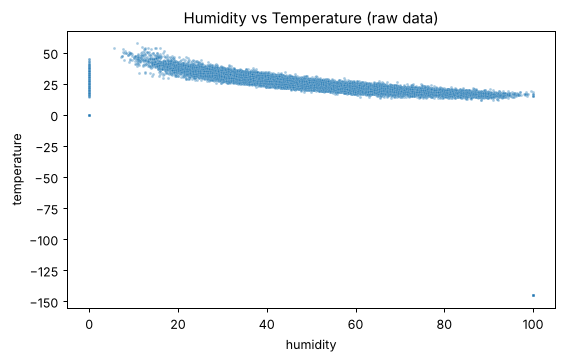

In [5]:
# Scatter plot to observe relationship (raw data, 20,000-row sample)
sample = df.sample(20000, random_state=42)
plt.figure(figsize=(7, 4))
sns.scatterplot(x="humidity", y="temperature", data=sample, s=5, alpha=0.4)
plt.title("Humidity vs Temperature (raw data)")
plt.show()

## Data Preprocessing
The raw data contains physically impossible readings (e.g. -145 °C, 0 % and 100 % humidity from faulty/saturated sensors). These are removed along with duplicates.

Rows before: 701548  Rows after: 662473
Correlation (clean): -0.906
Train: (529978, 1)  Test: (132495, 1)


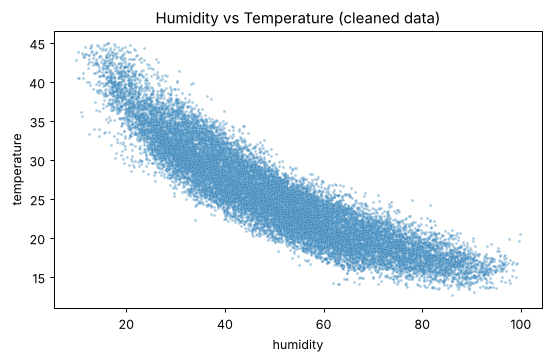

In [6]:
# Drop missing values, duplicates and faulty sensor readings
df_clean = df.dropna().drop_duplicates()
df_clean = df_clean[df_clean.temperature.between(-30, 45) &
                    df_clean.humidity.between(1, 99.9)]
print("Rows before:", len(df), " Rows after:", len(df_clean))
print("Correlation (clean):", round(df_clean.humidity.corr(df_clean.temperature), 3))

sample = df_clean.sample(20000, random_state=42)
plt.figure(figsize=(7, 4))
sns.scatterplot(x="humidity", y="temperature", data=sample, s=5, alpha=0.4)
plt.title("Humidity vs Temperature (cleaned data)")
plt.show()

# Define features and target
X = df_clean[["humidity"]]
y = df_clean["temperature"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

## Model Training

In [7]:
# Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)
print("Slope (coefficient):", round(model.coef_[0], 4))
print("Intercept          :", round(model.intercept_, 4))
print(f"Equation: Temperature = {model.coef_[0]:.4f} * Humidity + {model.intercept_:.4f}")

# Predict
y_pred = model.predict(X_test)

Slope (coefficient): -0.3095
Intercept          : 41.1278
Equation: Temperature = -0.3095 * Humidity + 41.1278


## Evaluation

MSE  : 6.8531
RMSE : 2.6178
R2   : 0.82


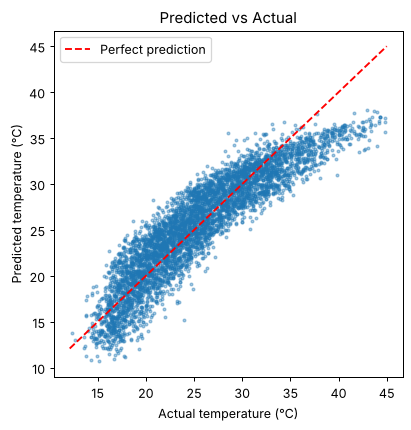

In [8]:
# Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
print("MSE  :", round(mse, 4))
print("RMSE :", round(np.sqrt(mse), 4))
print("R2   :", round(r2_score(y_test, y_pred), 4))

# Predicted vs Actual
idx = np.random.RandomState(0).choice(len(y_test), 5000, replace=False)
plt.figure(figsize=(5, 5))
plt.scatter(y_test.iloc[idx], y_pred[idx], s=5, alpha=0.4)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual temperature (°C)")
plt.ylabel("Predicted temperature (°C)")
plt.title("Predicted vs Actual")
plt.legend()
plt.show()

In [9]:
# Same model on the RAW (uncleaned) data, for comparison
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    df[["humidity"]], df["temperature"], test_size=0.2, random_state=42)
raw_pred = LinearRegression().fit(Xr_train, yr_train).predict(Xr_test)
print("Raw data   -> MSE:", round(mean_squared_error(yr_test, raw_pred), 2),
      " R2:", round(r2_score(yr_test, raw_pred), 4))
print("Clean data -> MSE:", round(mse, 2), " R2:", round(r2_score(y_test, y_pred), 4))

Raw data   -> MSE: 144.08  R2: 0.257
Clean data -> MSE: 6.85  R2: 0.82


In [10]:
# Predict temperature for new humidity values
new = pd.DataFrame({"humidity": [30, 50, 70]})
for h, t in zip(new.humidity, model.predict(new)):
    print(f"Humidity {h}% -> predicted temperature {t:.2f} °C")

Humidity 30% -> predicted temperature 31.84 °C
Humidity 50% -> predicted temperature 25.65 °C
Humidity 70% -> predicted temperature 19.46 °C


## Improvement: Polynomial Regression
The cleaned scatter plot curves slightly, so a degree-2 polynomial model is tested.

In [11]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

poly = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
poly.fit(X_train, y_train)
poly_pred = poly.predict(X_test)
print("Polynomial (deg 2) -> MSE:", round(mean_squared_error(y_test, poly_pred), 2),
      " R2:", round(r2_score(y_test, poly_pred), 4))
print("Linear             -> MSE:", round(mse, 2), " R2:", round(r2_score(y_test, y_pred), 4))

Polynomial (deg 2) -> MSE: 5.33  R2: 0.86
Linear             -> MSE: 6.85  R2: 0.82


## Conclusion
- Temperature has a strong **negative** relationship with humidity in this sensor data.
- Removing faulty sensor readings was the most important step: it raised R² from about 0.26 to about 0.82.
- A degree-2 polynomial model improves R² further to about 0.86.
- A single-feature Linear Regression explains most of the variation; adding pressure, location and time features or trying polynomial / tree-based models could improve it further.